# Module 09 — Support Vector Machines

**Applied exercises only** · ISLP, Chapter 9

**Printed textbook pages:** 396–398 (exercise starting pages)  

In [1]:
# Common imports: run this cell once before starting the exercises.
# All data sets come from the ISLP package installed in the project's .venv.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ISLP import load_data, confusion_table
from ISLP.svm import plot as plot_svm
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, GridSearchCV, KFold, StratifiedKFold

rng = np.random.default_rng(1)


def plot_decision(ax, model, X, y, title, transform=None, resolution=300):
    """Scatter the data and shade the model's predicted classes over a grid."""
    x_min, x_max = X[:, 0].min() - 0.1, X[:, 0].max() + 0.1
    y_min, y_max = X[:, 1].min() - 0.1, X[:, 1].max() + 0.1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, resolution), np.linspace(y_min, y_max, resolution))
    grid = np.c_[xx.ravel(), yy.ravel()]
    zz = model.predict(transform(grid) if transform else grid).reshape(xx.shape)
    ax.contourf(xx, yy, zz.astype(float), alpha=0.2, cmap="coolwarm")
    ax.scatter(X[:, 0], X[:, 1], c=y.astype(float), cmap="coolwarm", s=14, edgecolor="k", linewidth=0.3)
    ax.set(title=title, xlabel="X1", ylabel="X2")

---

## Exercise 4 · Applied

**Textbook: printed page 396**

Generate a simulated two-class data set with 100 observations and
two features in which there is a visible but non-linear separation between the two classes. Show that in this setting, a support vector
machine with a polynomial kernel (with degree greater than 1) or a
radial kernel will outperform a support vector classifier on the training data. Which technique performs best on the test data? Make
plots and report training and test error rates in order to back up
your assertions.

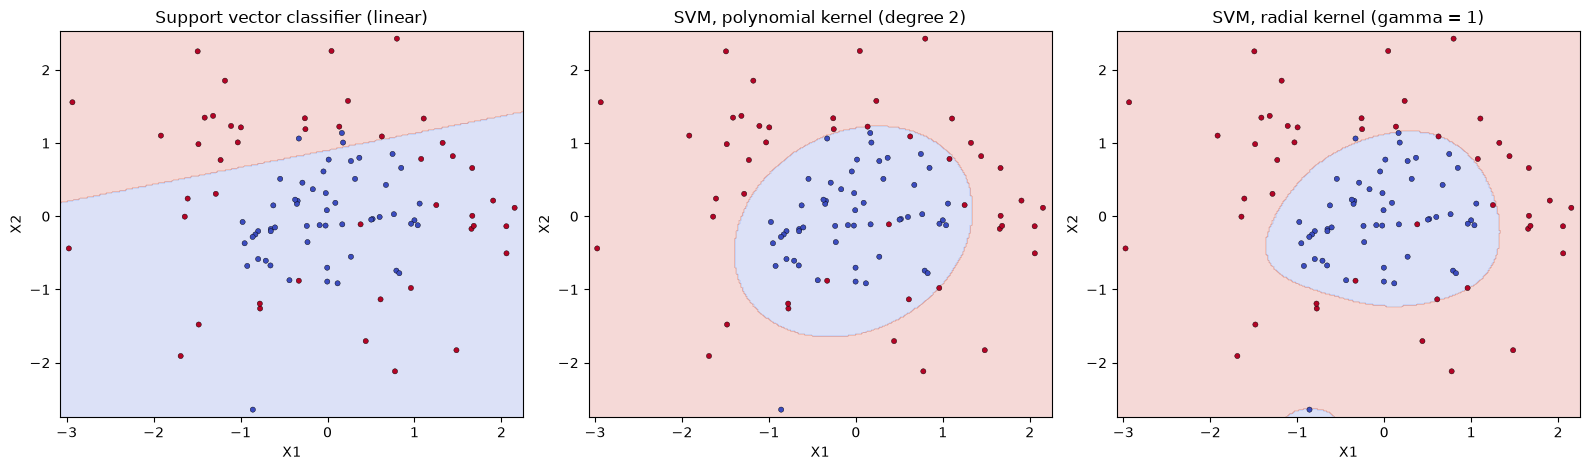

,training error,test error
model,,
Support vector classifier (linear),0.30,0.45
"SVM, polynomial kernel (degree 2)",0.09,0.19
"SVM, radial kernel (gamma = 1)",0.07,0.15


In [2]:
# Exercise 4
rng = np.random.default_rng(4)
X4 = rng.normal(size=(200, 2))
y4 = (X4[:, 0]**2 + X4[:, 1]**2 > 1.4).astype(int)        # circular boundary
flip = rng.choice(200, size=10, replace=False)             # a little label noise
y4[flip] = 1 - y4[flip]
X4_tr, X4_te, y4_tr, y4_te = X4[:100], X4[100:], y4[:100], y4[100:]   # 100 training observations

models_4 = {
    "Support vector classifier (linear)": SVC(kernel="linear", C=1),
    "SVM, polynomial kernel (degree 2)": SVC(kernel="poly", degree=2, coef0=1, C=1),
    "SVM, radial kernel (gamma = 1)": SVC(kernel="rbf", gamma=1, C=1),
}
rows = []
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, (name, model) in zip(axes, models_4.items()):
    model.fit(X4_tr, y4_tr)
    rows.append({"model": name,
                 "training error": np.mean(model.predict(X4_tr) != y4_tr),
                 "test error": np.mean(model.predict(X4_te) != y4_te)})
    plot_decision(ax, model, X4_tr, y4_tr, name)
plt.tight_layout()
plt.show()
pd.DataFrame(rows).set_index("model").round(3)

**Observations / conclusions**

I simulated 100 training and 100 test points with a circular class boundary ($X_1^2 + X_2^2 > 1.4$) and 5% label noise.

| model | training error | test error |
|---|---|---|
| Support vector classifier (linear) | 0.30 | 0.45 |
| SVM, polynomial kernel (degree 2) | 0.09 | 0.19 |
| SVM, radial kernel (γ = 1) | **0.07** | **0.15** |

A straight line can't separate a circle, so the linear classifier does little better than guessing on the test set. Both nonlinear kernels beat it on the training data, as the exercise asks us to show. The radial kernel is also best on the test data, with the degree-2 polynomial (which can represent a circle exactly) close behind.

---

## Exercise 5 · Applied

**Textbook: printed page 396**

We have seen that we can fit an SVM with a non-linear kernel in order
to perform classification using a non-linear decision boundary. We will
now see that we can also obtain a non-linear decision boundary by
performing logistic regression using non-linear transformations of the
features.

### Exercise 5(a)

Generate a data set with n = 500 and p = 2, such that the observations belong to two classes with a quadratic decision boundary
between them. For instance, you can do this as follows:
rng = np.random.default_rng(5)
x1 = rng.uniform(size=500) - 0.5
x2 = rng.uniform(size=500) - 0.5
y = x1**2 - x2**2 > 0

In [3]:
# Exercise 5(a)
rng = np.random.default_rng(5)
x1 = rng.uniform(size=500) - 0.5
x2 = rng.uniform(size=500) - 0.5
y5 = (x1**2 - x2**2 > 0).astype(int)
X5 = np.column_stack([x1, x2])
print(f"Class balance: {np.bincount(y5)}")

Class balance: [247 253]


### Exercise 5(b)

Plot the observations, colored according to their class labels.
Your plot should display X1 on the x-axis, and X2 on the yaxis.

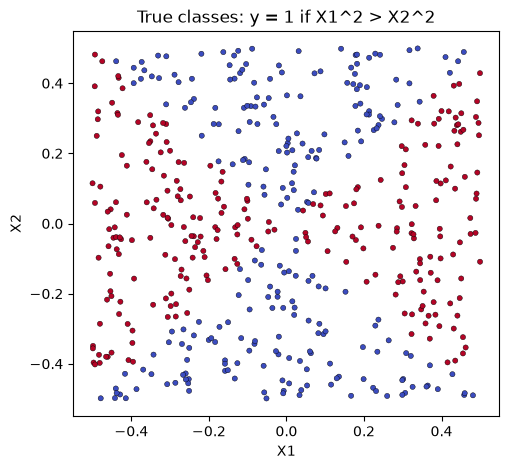

In [4]:
# Exercise 5(b)
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(x1, x2, c=y5, cmap="coolwarm", s=14, edgecolor="k", linewidth=0.3)
ax.set(xlabel="X1", ylabel="X2", title="True classes: y = 1 if X1^2 > X2^2")
plt.show()

### Exercise 5(c)

Fit a logistic regression model to the data, using X1 and X2 as
predictors.

In [5]:
# Exercise 5(c)
logit_lin = LogisticRegression().fit(X5, y5)
print("Coefficients:", logit_lin.coef_.round(4), "intercept:", logit_lin.intercept_.round(4))

Coefficients: [[-0.1514  0.0818]] intercept: [0.0222]


### Exercise 5(d)

Apply this model to the training data in order to obtain a predicted class label for each training observation. Plot the observations, colored according to the predicted class labels. The
decision boundary should be linear.

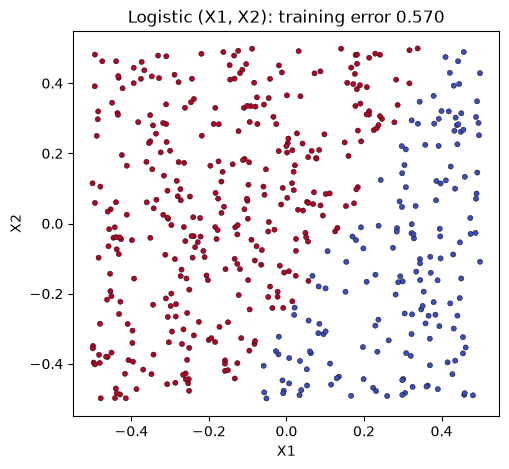

In [6]:
# Exercise 5(d)
pred_lin = logit_lin.predict(X5)
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(x1, x2, c=pred_lin, cmap="coolwarm", s=14, edgecolor="k", linewidth=0.3)
ax.set(xlabel="X1", ylabel="X2", title=f"Logistic (X1, X2): training error {np.mean(pred_lin != y5):.3f}")
plt.show()

### Exercise 5(e)

Now fit a logistic regression model to the data using non-linear
functions of X1 and X2 as predictors (e.g. X2
1, X1×X2, log(X2),
and so forth).

In [7]:
# Exercise 5(e)
def quad_features(X):
    return np.column_stack([X[:, 0], X[:, 1], X[:, 0]**2, X[:, 1]**2, X[:, 0] * X[:, 1]])

logit_quad = LogisticRegression(C=1e4, max_iter=10_000).fit(quad_features(X5), y5)
print("Features: X1, X2, X1^2, X2^2, X1*X2")
print("Coefficients:", logit_quad.coef_.round(2))

Features: X1, X2, X1^2, X2^2, X1*X2
Coefficients: [[  -1.56   -1.7   265.78 -269.59    0.53]]


### Exercise 5(f)

Apply this model to the training data in order to obtain a predicted class label for each training observation. Plot the observations, colored according to the predicted class labels. The
decision boundary should be obviously non-linear. If it is not,
then repeat (a)–(e) until you come up with an example in which
the predicted class labels are obviously non-linear.

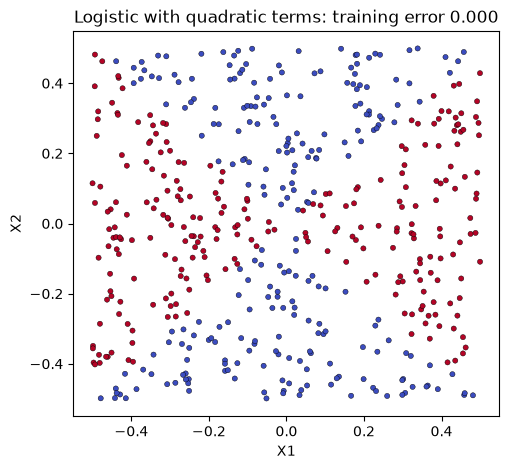

In [8]:
# Exercise 5(f)
pred_quad = logit_quad.predict(quad_features(X5))
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(x1, x2, c=pred_quad, cmap="coolwarm", s=14, edgecolor="k", linewidth=0.3)
ax.set(xlabel="X1", ylabel="X2", title=f"Logistic with quadratic terms: training error {np.mean(pred_quad != y5):.3f}")
plt.show()

### Exercise 5(g)

Fit a support vector classifier to the data with X1 and X2 as
predictors. Obtain a class prediction for each training observation. Plot the observations, colored according to the predicted
class labels.

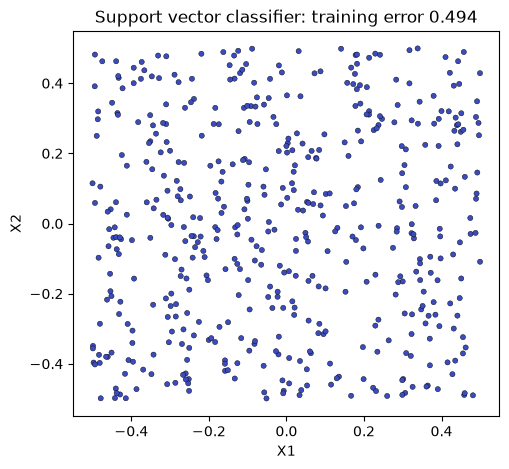

In [9]:
# Exercise 5(g)
svc5 = SVC(kernel="linear", C=1).fit(X5, y5)
pred_svc5 = svc5.predict(X5)
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(x1, x2, c=pred_svc5, cmap="coolwarm", s=14, edgecolor="k", linewidth=0.3)
ax.set(xlabel="X1", ylabel="X2", title=f"Support vector classifier: training error {np.mean(pred_svc5 != y5):.3f}")
plt.show()

### Exercise 5(h)

Fit a SVM using a non-linear kernel to the data. Obtain a class
prediction for each training observation. Plot the observations,
colored according to the predicted class labels.

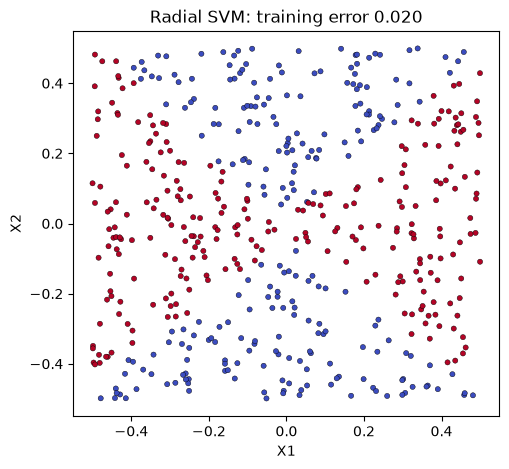

In [10]:
# Exercise 5(h)
svm5 = SVC(kernel="rbf", gamma=5, C=10).fit(X5, y5)
pred_svm5 = svm5.predict(X5)
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(x1, x2, c=pred_svm5, cmap="coolwarm", s=14, edgecolor="k", linewidth=0.3)
ax.set(xlabel="X1", ylabel="X2", title=f"Radial SVM: training error {np.mean(pred_svm5 != y5):.3f}")
plt.show()

### Exercise 5(i)

Comment on your results.

In [11]:
# Exercise 5(i)
pd.Series({
    "Logistic, linear terms": np.mean(pred_lin != y5),
    "Logistic, quadratic terms": np.mean(pred_quad != y5),
    "Support vector classifier": np.mean(pred_svc5 != y5),
    "Radial-kernel SVM": np.mean(pred_svm5 != y5),
}, name="training error").round(3).to_frame()

,training error
"Logistic, linear terms",0.570
"Logistic, quadratic terms",0.000
Support vector classifier,0.494
Radial-kernel SVM,0.020


**Observations / conclusions**

The true boundary $X_1^2 = X_2^2$ is a pair of crossing diagonal lines.
- Logistic regression on $X_1, X_2$ (d) and the linear support vector classifier (g) can only draw one straight line. They do no better than chance (training error 0.57 and 0.49).
- Logistic regression with $X_1^2$, $X_2^2$ and $X_1X_2$ (e, f) recovers the boundary essentially perfectly (training error 0.000). Its coefficients on $X_1^2$ and $X_2^2$ are large and of opposite sign, which is exactly the true rule.
- A radial-kernel SVM (h) also finds the nonlinear "X" shape (training error 0.02) without being told which features to use.

So with the right hand-crafted features, logistic regression matches a kernel SVM. The kernel's advantage is that you don't need to know those features in advance; the trade-off is tuning C and γ.

---

## Exercise 6 · Applied

**Textbook: printed page 397**

At the end of Section 9.6.1, it is claimed that in the case of data that is
just barely linearly separable, a support vector classifier with a small
value of C that misclassifies a couple of training observations may
perform better on test data than one with a huge value of C that does
not misclassify any training observations. You will now investigate
this claim.

### Exercise 6(a)

Generate two-class data with p = 2 in such a way that the classes
are just barely linearly separable.

Training set: 106 observations ([51 55] per class)


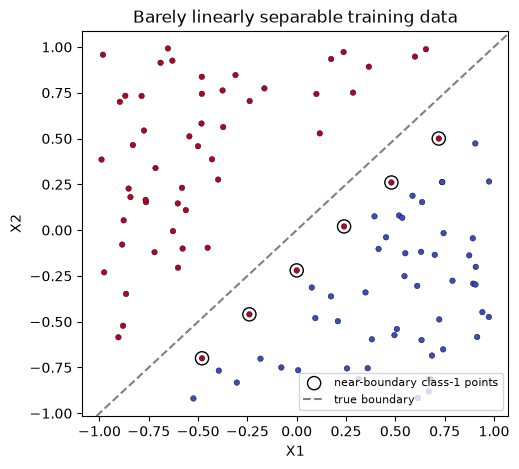

In [12]:
# Exercise 6(a)
# True boundary: X2 = X1. The bulk of each class sits well away from it (|X2 - X1| > 0.3), but six
# class-1 points lie just on the wrong side of the true boundary (X2 - X1 = -0.22). The data are still
# linearly separable, but only by a line squeezed up against class 0.
rng = np.random.default_rng(6)
X = rng.uniform(-1, 1, size=(400, 2))
gap = X[:, 1] - X[:, 0]
keep = np.abs(gap) > 0.3
X_bulk, y_bulk = X[keep][:100], (gap[keep][:100] > 0).astype(int)
t = np.linspace(-0.6, 0.6, 6)
X_edge = np.c_[t + 0.12, t - 0.10]
X6_tr = np.vstack([X_bulk, X_edge])
y6_tr = np.r_[y_bulk, np.ones(6, dtype=int)]
print(f"Training set: {len(y6_tr)} observations ({np.bincount(y6_tr)} per class)")

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(X6_tr[:, 0], X6_tr[:, 1], c=y6_tr, cmap="coolwarm", s=16, edgecolor="k", linewidth=0.3)
ax.scatter(X_edge[:, 0], X_edge[:, 1], facecolor="none", edgecolor="k", s=90, label="near-boundary class-1 points")
ax.axline((0, 0), slope=1, color="gray", ls="--", label="true boundary")
ax.set(title="Barely linearly separable training data", xlabel="X1", ylabel="X2")
ax.legend(loc="lower right", fontsize=8)
plt.show()

### Exercise 6(b)

Compute the cross-validation error rates for support vector
classifiers with a range of C values. How many training observations are misclassified for each value of C considered, and how
does this relate to the cross-validation errors obtained?

In [13]:
# Exercise 6(b)
Cs = [0.01, 0.1, 1, 10, 100, 1e4, 1e6]
cv6 = StratifiedKFold(10, shuffle=True, random_state=0)
grid6 = GridSearchCV(SVC(kernel="linear"), {"C": Cs}, cv=cv6, scoring="accuracy").fit(X6_tr, y6_tr)
table6 = pd.DataFrame({"C": Cs, "CV error": 1 - grid6.cv_results_["mean_test_score"]})
table6["training errors (count)"] = [int(np.sum(SVC(kernel="linear", C=C).fit(X6_tr, y6_tr).predict(X6_tr) != y6_tr)) for C in Cs]
table6.set_index("C").round(4)

,CV error,training errors (count)
C,,
0.01,0.3391,25
0.10,0.0582,6
1.00,0.0582,6
10.00,0.0491,2
100.00,0.0000,0
10000.00,0.0000,0
1000000.00,0.0000,0


### Exercise 6(c)

Generate an appropriate test data set, and compute the test
errors corresponding to each of the values of C considered. Which
value of C leads to the fewest test errors, and how does this
compare to the values of C that yield the fewest training errors
and the fewest cross-validation errors?

In [14]:
# Exercise 6(c)
# Test data come from the same underlying rule (class = X2 > X1), uniformly over the square.
rng_te = np.random.default_rng(66)
X6_te = rng_te.uniform(-1, 1, size=(5000, 2))
y6_te = (X6_te[:, 1] - X6_te[:, 0] > 0).astype(int)
table6["test error"] = [np.mean(SVC(kernel="linear", C=C).fit(X6_tr, y6_tr).predict(X6_te) != y6_te) for C in Cs]
display(table6.set_index("C").round(4))
print("Fewest training errors at C =", list(table6.loc[table6["training errors (count)"] == table6["training errors (count)"].min(), "C"]))
print("Lowest CV error at C =", list(table6.loc[table6["CV error"] == table6["CV error"].min(), "C"]))
print("Lowest test error at C =", table6.loc[table6["test error"].idxmin(), "C"])

,CV error,training errors (count),test error
C,,,
0.01,0.3391,25,0.3322
0.10,0.0582,6,0.0484
1.00,0.0582,6,0.0232
10.00,0.0491,2,0.0970
100.00,0.0000,0,0.1298
10000.00,0.0000,0,0.1160
1000000.00,0.0000,0,0.1160


Fewest training errors at C = [100.0, 10000.0, 1000000.0]
Lowest CV error at C = [100.0, 10000.0, 1000000.0]
Lowest test error at C = 1.0


### Exercise 6(d)

Discuss your results.

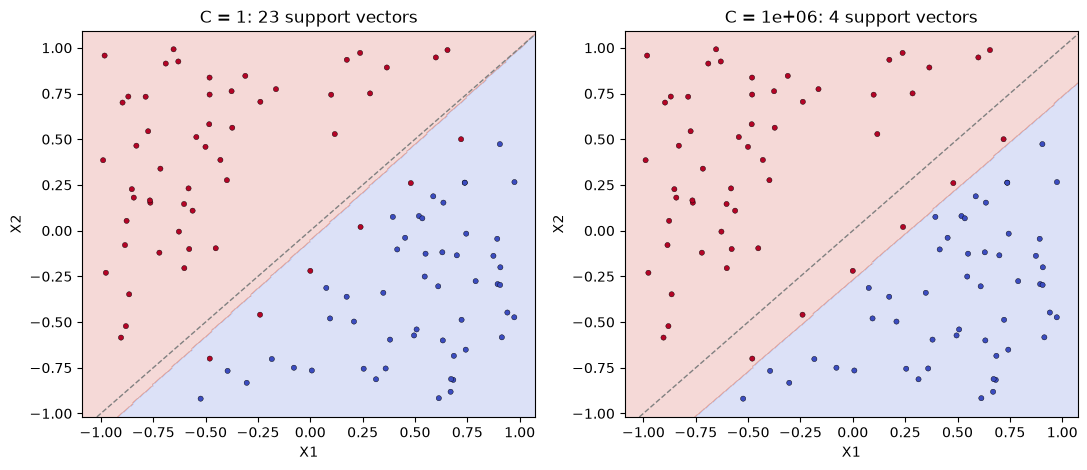

In [15]:
# Exercise 6(d)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, C in zip(axes, [1, 1e6]):
    m = SVC(kernel="linear", C=C).fit(X6_tr, y6_tr)
    plot_decision(ax, m, X6_tr, y6_tr, f"C = {C:g}: {len(m.support_)} support vectors")
    ax.axline((0, 0), slope=1, color="gray", ls="--", lw=1)
plt.tight_layout()
plt.show()

**Observations / conclusions**

The training data are linearly separable, but only by a line squeezed against class 0, because six class-1 points sit slightly on the wrong side of the true boundary.

- **(b)** With C ≥ 100 the classifier makes **0 training errors**, and its 10-fold CV error is also 0. With C = 0.1–1 it misclassifies those **6** points, and C = 0.01 is so soft that it misclassifies 25. CV favours large C here, because the near-boundary points appear in every fold.
- **(c)** On 5,000 fresh test points from the true rule, the **lowest test error is at C = 1 (2.3%)**. The C values with zero training/CV error give 11.6–13.0% test error, about five times worse.
- **(d)** This confirms the claim in Section 9.6.1. A huge C forces the hyperplane to accommodate every training point, so it tilts and shifts toward class 0 to fit a few unusual observations. A moderate C accepts a few training mistakes, keeps a wider margin that depends on many support vectors, and generalises much better. Low training error, and even low CV error when the awkward points are present in every fold, don't guarantee low test error.

---

## Exercise 7 · Applied

**Textbook: printed page 398**

In this problem, you will use support vector approaches in order to
predict whether a given car gets high or low gas mileage based on the
Auto data set.

### Exercise 7(a)

Create a binary variable that takes on a 1 for cars with gas
mileage above the median, and a 0 for cars with gas mileage
below the median.

In [16]:
# Exercise 7(a)
Auto = load_data("Auto")
Auto["mpg01"] = (Auto["mpg"] > Auto["mpg"].median()).astype(int)
Xa = Auto.drop(columns=["mpg", "mpg01"])
ya = Auto["mpg01"]
print(ya.value_counts())
cv7 = StratifiedKFold(10, shuffle=True, random_state=0)

mpg01
0    196
1    196
Name: count, dtype: int64


### Exercise 7(b)

Fit a support vector classifier to the data with various values of
C, in order to predict whether a car gets high or low gas mileage.
Report the cross-validation errors associated with different values of this parameter. Comment on your results. Note you will
need to fit the classifier without the gas mileage variable to produce sensible results.

In [17]:
# Exercise 7(b)
lin7 = GridSearchCV(make_pipeline(StandardScaler(), SVC(kernel="linear")),
                    {"svc__C": [0.001, 0.01, 0.1, 1, 10, 100]}, cv=cv7).fit(Xa, ya)
cv_lin7 = pd.Series(1 - lin7.cv_results_["mean_test_score"], index=[0.001, 0.01, 0.1, 1, 10, 100], name="CV error")
cv_lin7.index.name = "C"
cv_lin7.round(4).to_frame()

,CV error
C,
0.001,0.1250
0.010,0.0918
0.100,0.0944
1.000,0.0842
10.000,0.0894
100.000,0.0894


### Exercise 7(c)

Now repeat (b), this time using SVMs with radial and polynomial basis kernels, with different values of gamma and degree and
C. Comment on your results.

In [18]:
# Exercise 7(c)
rbf7 = GridSearchCV(make_pipeline(StandardScaler(), SVC(kernel="rbf")),
                    {"svc__C": [0.1, 1, 10, 100], "svc__gamma": [0.01, 0.1, 0.5, 1, 5]}, cv=cv7).fit(Xa, ya)
poly7 = GridSearchCV(make_pipeline(StandardScaler(), SVC(kernel="poly", coef0=1)),
                     {"svc__C": [0.01, 0.1, 1, 10], "svc__degree": [2, 3, 4]}, cv=cv7).fit(Xa, ya)
rbf_tbl = pd.DataFrame(rbf7.cv_results_["params"]).assign(cv_error=1 - rbf7.cv_results_["mean_test_score"])
poly_tbl = pd.DataFrame(poly7.cv_results_["params"]).assign(cv_error=1 - poly7.cv_results_["mean_test_score"])
print("Radial kernel: CV error by C (rows) and gamma (columns)")
display(rbf_tbl.pivot(index="svc__C", columns="svc__gamma", values="cv_error").round(4))
print("Polynomial kernel: CV error by C (rows) and degree (columns)")
display(poly_tbl.pivot(index="svc__C", columns="svc__degree", values="cv_error").round(4))
pd.DataFrame({
    "best params": [lin7.best_params_, rbf7.best_params_, poly7.best_params_],
    "CV error": [1 - g.best_score_ for g in (lin7, rbf7, poly7)],
}, index=["linear", "radial", "polynomial"]).round(4)

Radial kernel: CV error by C (rows) and gamma (columns)


svc__gamma,0.01,0.10,0.50,1.00,5.00
svc__C,,,,,
0.1,0.1097,0.0892,0.0892,0.0917,0.4276
1.0,0.0892,0.0841,0.0739,0.0713,0.0841
10.0,0.0842,0.0840,0.0790,0.0868,0.0994
100.0,0.0843,0.0842,0.0943,0.0867,0.0994


Polynomial kernel: CV error by C (rows) and degree (columns)


svc__degree,2,3,4
svc__C,,,
0.01,0.1020,0.0867,0.0944
0.10,0.0944,0.0918,0.0892
1.00,0.0842,0.0943,0.0892
10.00,0.0893,0.0943,0.0918


,best params,CV error
linear,{'svc__C': 1},0.0842
radial,"{'svc__C': 1, 'svc__gamma': 1}",0.0713
polynomial,"{'svc__C': 1, 'svc__degree': 2}",0.0842


### Exercise 7(d)

Make some plots to back up your assertions in (b) and (c).

**Hint:** In the lab, we used the plot_svm() function for fitted SVMs.
When p > 2, you can use the keyword argument features to
create plots displaying pairs of variables at a time.

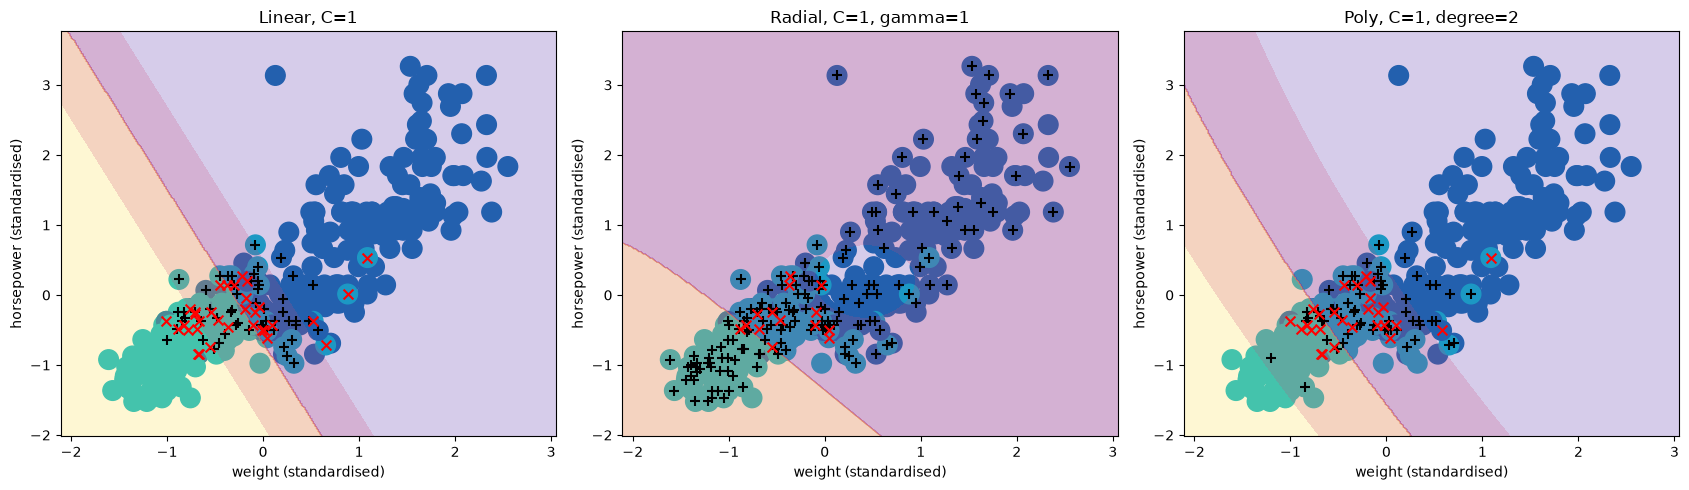

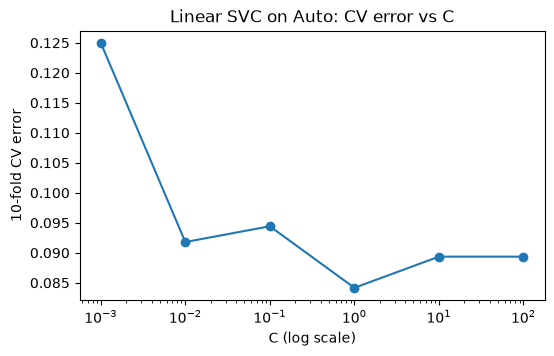

In [19]:
# Exercise 7(d)
# Plot each fitted kernel in the (weight, horsepower) plane, holding the other features at their means,
# using ISLP's plot_svm (features = indices of the two variables to show).
Xs = StandardScaler().fit_transform(Xa)
cols = list(Xa.columns)
f_idx = (cols.index("weight"), cols.index("horsepower"))
fits = {
    f"Linear, C={lin7.best_params_['svc__C']}": SVC(kernel="linear", C=lin7.best_params_["svc__C"]),
    f"Radial, C={rbf7.best_params_['svc__C']}, gamma={rbf7.best_params_['svc__gamma']}":
        SVC(kernel="rbf", C=rbf7.best_params_["svc__C"], gamma=rbf7.best_params_["svc__gamma"]),
    f"Poly, C={poly7.best_params_['svc__C']}, degree={poly7.best_params_['svc__degree']}":
        SVC(kernel="poly", coef0=1, C=poly7.best_params_["svc__C"], degree=poly7.best_params_["svc__degree"]),
}
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (name, model) in zip(axes, fits.items()):
    model.fit(Xs, ya)
    plot_svm(Xs, ya.to_numpy(), model, features=f_idx, ax=ax)
    ax.set(title=name, xlabel="weight (standardised)", ylabel="horsepower (standardised)")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(cv_lin7.index, cv_lin7.values, marker="o")
ax.set(xscale="log", xlabel="C (log scale)", ylabel="10-fold CV error", title="Linear SVC on Auto: CV error vs C")
plt.show()

**Observations / conclusions**

(All features are standardised, and `mpg` itself is excluded.)
- **(b)** Linear SVC: 10-fold CV error is 12.5% at C = 0.001 and about 8.4–9.4% for C between 0.01 and 100, with the minimum at C = 1 (8.4%). Once C is above a very small value, the results are insensitive to it.
- **(c)** The radial kernel does best, at **7.1% CV error with C = 1, γ = 1**. With a very large γ (5) and small C (0.1), the CV error jumps to 43%: each point's kernel is very narrow and the small C limits the fit, so the model ends up predicting mostly one class. The best polynomial kernel (degree 2, C = 1) reaches 8.4%, the same as the linear model. Higher degrees don't help.
- **(d)** In the (weight, horsepower) plane, the linear boundary is a straight diagonal: heavy, powerful cars are low-mpg. The radial boundary curves slightly around the cluster of light cars. Since the improvement is only ~1 percentage point, the classes are almost linearly separable, and a linear SVC is nearly as good as the nonlinear kernels.

---

## Exercise 8 · Applied

**Textbook: printed page 398**

This problem involves the OJ data set which is part of the ISLP
package.

### Exercise 8(a)

Create a training set containing a random sample of 800 observations, and a test set containing the remaining observations.

In [20]:
# Exercise 8(a)
OJ = load_data("OJ")
Xo = pd.get_dummies(OJ.drop(columns="Purchase"), drop_first=True, dtype=float)
yo = OJ["Purchase"]
Xo_tr, Xo_te, yo_tr, yo_te = train_test_split(Xo, yo, train_size=800, random_state=1)
print(Xo_tr.shape, Xo_te.shape)
cv8 = KFold(10, shuffle=True, random_state=1)
Cs8 = [0.01, 0.03, 0.1, 0.3, 1, 3, 10]
results_8 = []

def errors(model):
    return np.mean(model.predict(Xo_tr) != yo_tr), np.mean(model.predict(Xo_te) != yo_te)

(800, 17) (270, 17)


### Exercise 8(b)

Fit a support vector classifier to the training data using
C = 0.01, with Purchase as the response and the other variables
as predictors. How many support points are there?

In [21]:
# Exercise 8(b)
# Features are standardised inside a pipeline so C has the same meaning for every variable.
svc8 = make_pipeline(StandardScaler(), SVC(kernel="linear", C=0.01)).fit(Xo_tr, yo_tr)
n_sv = svc8[-1].n_support_
print(f"Support points: {n_sv.sum()} ({dict(zip(svc8[-1].classes_, n_sv))}) out of {len(yo_tr)}")

Support points: 433 ({'CH': np.int32(217), 'MM': np.int32(216)}) out of 800


### Exercise 8(c)

What are the training and test error rates?

In [22]:
# Exercise 8(c)
tr_err, te_err = errors(svc8)
results_8.append({"model": "Linear, C=0.01", "train error": tr_err, "test error": te_err})
print(f"Training error {tr_err:.4f}, test error {te_err:.4f}")

Training error 0.1675, test error 0.1667


### Exercise 8(d)

Use cross-validation to select an optimal C. Consider values in
the range 0.01 to 10.

In [23]:
# Exercise 8(d)
grid_lin = GridSearchCV(make_pipeline(StandardScaler(), SVC(kernel="linear")), {"svc__C": Cs8},
                        cv=cv8).fit(Xo_tr, yo_tr)
print(pd.Series(1 - grid_lin.cv_results_["mean_test_score"], index=Cs8, name="CV error").round(4).to_string())
print("Best C:", grid_lin.best_params_["svc__C"])

0.01     0.1712
0.03     0.1725
0.10     0.1700
0.30     0.1687
1.00     0.1725
3.00     0.1725
10.00    0.1700
Best C: 0.3


### Exercise 8(e)

Compute the training and test error rates using this new value
for C.

In [24]:
# Exercise 8(e)
tr_err, te_err = errors(grid_lin.best_estimator_)
results_8.append({"model": f"Linear, C={grid_lin.best_params_['svc__C']} (CV)", "train error": tr_err, "test error": te_err})
print(f"Training error {tr_err:.4f}, test error {te_err:.4f}")

Training error 0.1625, test error 0.1815


### Exercise 8(f)

Repeat parts (b) through (e) using a support vector machine
with a radial kernel. Use the default value for gamma.

In [25]:
# Exercise 8(f): radial kernel, default gamma ("scale")
rbf8 = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=0.01)).fit(Xo_tr, yo_tr)
print(f"C=0.01: {rbf8[-1].n_support_.sum()} support points")
tr_err, te_err = errors(rbf8)
results_8.append({"model": "Radial, C=0.01", "train error": tr_err, "test error": te_err})
print(f"C=0.01: training error {tr_err:.4f}, test error {te_err:.4f}")

grid = GridSearchCV(make_pipeline(StandardScaler(), SVC(kernel="rbf")), {"svc__C": Cs8},
                    cv=cv8).fit(Xo_tr, yo_tr)
print(pd.Series(1 - grid.cv_results_["mean_test_score"], index=Cs8, name="CV error").round(4).to_string())
best_C = grid.best_params_["svc__C"]
tr_err, te_err = errors(grid.best_estimator_)
results_8.append({"model": f"Radial, C={best_C} (CV)", "train error": tr_err, "test error": te_err})
print(f"Best C = {best_C}: training error {tr_err:.4f}, test error {te_err:.4f}")

C=0.01: 613 support points
C=0.01: training error 0.3800, test error 0.4185


0.01     0.3800
0.03     0.3800
0.10     0.1887
0.30     0.1838
1.00     0.1825
3.00     0.1862
10.00    0.1950
Best C = 1: training error 0.1525, test error 0.1926


### Exercise 8(g)

Repeat parts (b) through (e) using a support vector machine
with a polynomial kernel. Set degree = 2.

In [26]:
# Exercise 8(g): polynomial kernel, degree 2
poly8 = make_pipeline(StandardScaler(), SVC(kernel="poly", degree=2, C=0.01)).fit(Xo_tr, yo_tr)
print(f"C=0.01: {poly8[-1].n_support_.sum()} support points")
tr_err, te_err = errors(poly8)
results_8.append({"model": "Poly deg 2, C=0.01", "train error": tr_err, "test error": te_err})
print(f"C=0.01: training error {tr_err:.4f}, test error {te_err:.4f}")

grid = GridSearchCV(make_pipeline(StandardScaler(), SVC(kernel="poly", degree=2)), {"svc__C": Cs8},
                    cv=cv8).fit(Xo_tr, yo_tr)
print(pd.Series(1 - grid.cv_results_["mean_test_score"], index=Cs8, name="CV error").round(4).to_string())
best_C = grid.best_params_["svc__C"]
tr_err, te_err = errors(grid.best_estimator_)
results_8.append({"model": f"Poly deg 2, C={best_C} (CV)", "train error": tr_err, "test error": te_err})
print(f"Best C = {best_C}: training error {tr_err:.4f}, test error {te_err:.4f}")

C=0.01: 614 support points
C=0.01: training error 0.3588, test error 0.4000


0.01     0.3787
0.03     0.3512
0.10     0.3263
0.30     0.2575
1.00     0.2263
3.00     0.2175
10.00    0.2113
Best C = 10: training error 0.2025, test error 0.2593


### Exercise 8(h)

Overall, which approach seems to give the best results on this
data?

In [27]:
# Exercise 8(h)
pd.DataFrame(results_8).set_index("model").round(4)

,train error,test error
model,,
"Linear, C=0.01",0.1675,0.1667
"Linear, C=0.3 (CV)",0.1625,0.1815
"Radial, C=0.01",0.3800,0.4185
"Radial, C=1 (CV)",0.1525,0.1926
"Poly deg 2, C=0.01",0.3588,0.4000
"Poly deg 2, C=10 (CV)",0.2025,0.2593


**Observations / conclusions**

(Features standardised; 800 training and 270 test observations.)
- **(b)** The linear SVC with C = 0.01 uses **433 support points** of 800 (217 CH, 216 MM). Such a soft margin means most points influence the fit.
- **(c)** Training error 16.8%, test error 16.7%.
- **(d, e)** CV error is almost flat across C ∈ [0.01, 10] (16.9–17.3%). CV picks C = 0.3, which gives training error 16.3% and test error 18.1%. The difference from C = 0.01 is noise, about 4 test observations.
- **(f)** Radial kernel (default γ): C = 0.01 is far too soft and predicts nearly everything as CH (38% training error). CV picks C = 1, giving training error 15.3% and test error 19.3%.
- **(g)** Polynomial kernel, degree 2: CV picks C = 10. Training error is 20.3% and test error 25.9%, the worst of the three.
- **(h)** The **linear support vector classifier** gives the best (and most stable) test error, about 17–18%. The radial kernel fits the training data slightly better but doesn't generalise better. The OJ decision depends mainly on `LoyalCH` and price differences in a roughly linear way, so extra flexibility doesn't pay off.